In [1]:
# cell 1
import pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv("../results/exp01_classical.csv")
cols = ["gap_vs_driver", "zone_sw", "sim_to_driver", "secs"]
df.groupby("method")[cols].agg(["mean", "median"]).round(3)

gap_vs_driver        zone_sw        sim_to_driver           secs  \
                  mean median    mean median          mean median    mean   
method                                                                      
driver           0.000  0.000  21.850   22.0         1.000  1.000   0.000   
lns             -0.120 -0.112  35.768   35.0        -0.012 -0.012  13.125   
nn               0.022  0.023  40.865   41.0        -0.012 -0.020   0.000   
sa              -0.100 -0.095  37.386   37.0        -0.008 -0.002  14.174   
zone_lns         0.008  0.004  19.725   20.0        -0.014 -0.066   0.293   
zone_sa          0.005  0.002  19.725   20.0        -0.014 -0.065   4.239   

                  
          median  
method            
driver     0.000  
lns       11.899  
nn         0.000  
sa        15.231  
zone_lns   0.309  
zone_sa    4.470

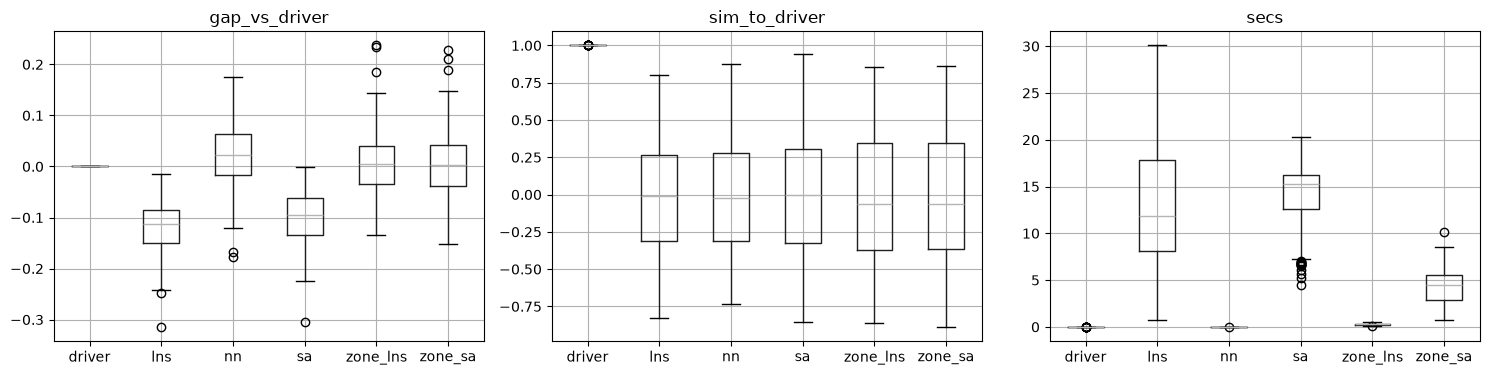

In [2]:
# cell 2: spread, not just means
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ["gap_vs_driver", "sim_to_driver", "secs"]):
    df.boxplot(column=c, by="method", ax=a); a.set_title(c); a.set_xlabel("")
plt.suptitle(""); plt.tight_layout(); plt.show()

In [3]:
# cell 3: does the answer depend on route size?
df["size"] = pd.cut(df.n, [0, 100, 150, 200, 300])
df.pivot_table(index="size", columns="method", values="gap_vs_driver", observed=True).round(3)

method,driver,lns,nn,sa,zone_lns,zone_sa
size,,,,,,
"(0, 100]",0.0,-0.175,-0.047,-0.162,-0.018,-0.018
"(100, 150]",0.0,-0.122,0.011,-0.104,-0.001,-0.004
"(150, 200]",0.0,-0.112,0.038,-0.090,0.018,0.015
"(200, 300]",0.0,-0.055,0.137,-0.039,0.057,0.032


In [ ]:
# cell 5 (markdown): conclusions: SA vs LNS, general vs zone-wise, trade-off cost vs driver similarity

In [5]:
import pandas as pd, numpy as np
df = pd.read_csv("../results/exp01_classical.csv")
p = df.pivot(index="route", columns="method", values="gap_vs_driver")

def diff(a, b):
    d = (p[a] - p[b]).dropna(); return f"{a} - {b}: mean {d.mean():+.4f}  95% CI ±{1.96*d.sem():.4f}  (n={len(d)})"
print(diff("lns", "sa")); print(diff("zone_lns", "zone_sa")); print(diff("zone_lns", "driver"))

df["size"] = pd.cut(df.n, [0, 100, 150, 200, 300])
df.pivot_table(index="size", columns="method", values="gap_vs_driver", observed=True).round(3)

lns - sa: mean -0.0198  95% CI ±0.0025  (n=207)
zone_lns - zone_sa: mean +0.0033  95% CI ±0.0017  (n=207)
zone_lns - driver: mean +0.0085  95% CI ±0.0080  (n=207)


method,driver,lns,nn,sa,zone_lns,zone_sa
size,,,,,,
"(0, 100]",0.0,-0.175,-0.047,-0.162,-0.018,-0.018
"(100, 150]",0.0,-0.122,0.011,-0.104,-0.001,-0.004
"(150, 200]",0.0,-0.112,0.038,-0.090,0.018,0.015
"(200, 300]",0.0,-0.055,0.137,-0.039,0.057,0.032


In [6]:
import numpy as np, pandas as pd
from lmr import load_routes, split, SOLVERS
from lmr.evaluate import zone_order_similarity

_, _, test = split(load_routes(1000))
print(len(test), "test routes")

rows = []
for r in test:
    for name in ["zone_lns", "nn"]:                       # fast methods, ~1-2 min total
        p = SOLVERS[name](r)
        rows.append(dict(route=r.rid, n_zones=len(r.zone_names), method=name,
                         zone_order_sim=zone_order_similarity(r, p)))
zdf = pd.DataFrame(rows)
print(zdf.groupby("method").zone_order_sim.agg(["mean", "median", "std"]).round(3))

207 test routes
           mean  median    std
method                        
nn       -0.010  -0.067  0.483
zone_lns -0.034  -0.095  0.486
